# GPU-Based Sobel Edge Detection

This notebook investigates the performance of GPU-based image processing using Sobel edge detection.

The experiments use Python, NumPy, and Numba CUDA to implement and evaluate image processing on a GPU. The main objective is to study GPU execution, memory transfers, and performance across different image resolutions.

In [ ]:
!nvidia-smi

Mon Nov  9 10:21:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import numpy as np
import numba
from numba import cuda

print("NumPy version:", np.__version__)
print("Numba version:", numba.__version__)
print("CUDA available:", cuda.is_available())

NumPy version: 2.4.6
Numba version: 0.64.0
CUDA available: True


## GPU Memory Management

GPU computing requires data to be transferred between CPU memory (host memory) and GPU memory (device memory).

This experiment demonstrates how to create arrays in CPU memory, transfer them to GPU memory, allocate device memory, and retrieve data back to the CPU using Numba CUDA.

In [ ]:
# Create an array in CPU memory
A = np.array([10, 20, 30, 40, 50], dtype=np.float32)

print("Original array:", A)
print("Array type:", type(A))
print("Array location: CPU memory")

Original array: [10. 20. 30. 40. 50.]
Array type: <class 'numpy.ndarray'>
Array location: CPU memory


In [ ]:
# Transfer data from CPU to GPU
d_A = cuda.to_device(A)

print("Original CPU array:", A)
print("GPU array:", d_A.copy_to_host())
print("GPU array type:", type(d_A))

Original CPU array: [10. 20. 30. 40. 50.]
GPU array: [10. 20. 30. 40. 50.]
GPU array type: <class 'numba.cuda.cudadrv.devicearray.DeviceNDArray'>


In [ ]:
# Allocate an empty array in GPU memory
d_B = cuda.device_array(5, dtype=np.float32)

print("GPU memory allocated successfully.")
print("Allocated array:", d_B.copy_to_host())

GPU memory allocated successfully.
Allocated array: [0. 0. 0. 0. 0.]


In [ ]:
# Copy GPU data back to CPU
B = d_A.copy_to_host()

print("Data copied from GPU to CPU:", B)
print("CPU array type:", type(B))

Data copied from GPU to CPU: [10. 20. 30. 40. 50.]
CPU array type: <class 'numpy.ndarray'>


In [ ]:
if np.array_equal(A, B):
    print("Memory transfer verification successful!")
else:
    print("Memory transfer verification failed!")

Memory transfer verification successful!


## Input Image Generation

In this experiment, we generate grayscale images of different resolutions to evaluate Sobel edge detection.

The same input images will be used for both CPU and GPU implementations to ensure a fair performance comparison.

We will experiment with multiple image sizes to study how workload size affects GPU performance.

In [ ]:
import numpy as np

# Generate a reproducible grayscale image
np.random.seed(42)

image_size = 256
image = np.random.randint(
    0, 256,
    size=(image_size, image_size),
    dtype=np.uint8
)

print("Image shape:", image.shape)
print("Image data type:", image.dtype)
print("Minimum pixel value:", image.min())
print("Maximum pixel value:", image.max())

Image shape: (256, 256)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


## CPU Implementation of Sobel Edge Detection

The Sobel operator is an edge detection technique that identifies intensity changes in an image by calculating horizontal and vertical gradients.

The Sobel operator is implemented using NumPy on the CPU. The horizontal gradient (Gx), vertical gradient (Gy), and gradient magnitude are calculated.

In this experiment, Sobel edge detection is implemented on the CPU. The resulting edge image will serve as a reference for verifying the GPU implementation and comparing execution performance.


In [ ]:
import numpy as np
import time

def sobel_cpu(image):

    # Convert image to float32
    img = image.astype(np.float32)

    height, width = img.shape

    # Initialize gradient arrays
    gx = np.zeros((height, width), dtype=np.float32)
    gy = np.zeros((height, width), dtype=np.float32)

    # Calculate horizontal gradient
    gx[1:-1, 1:-1] = (
        -img[:-2, :-2] + img[:-2, 2:]
        - 2 * img[1:-1, :-2] + 2 * img[1:-1, 2:]
        - img[2:, :-2] + img[2:, 2:]
    )

    # Calculate vertical gradient
    gy[1:-1, 1:-1] = (
        -img[:-2, :-2] - 2 * img[:-2, 1:-1] - img[:-2, 2:]
        + img[2:, :-2] + 2 * img[2:, 1:-1] + img[2:, 2:]
    )

    # Calculate gradient magnitude
    edges = np.sqrt(gx * gx + gy * gy)

    return edges


# Execute CPU Sobel edge detection
start_time = time.perf_counter()

cpu_edges = sobel_cpu(image)

cpu_time = time.perf_counter() - start_time

print("CPU Sobel execution completed.")
print("Input image shape:", image.shape)
print("Output image shape:", cpu_edges.shape)
print("Output data type:", cpu_edges.dtype)
print("Execution time:", cpu_time, "seconds")
print("Minimum edge value:", cpu_edges.min())
print("Maximum edge value:", cpu_edges.max())

CPU Sobel execution completed.
Input image shape: (256, 256)
Output image shape: (256, 256)
Output data type: float32
Execution time: 0.0051466569998410705 seconds
Minimum edge value: 0.0
Maximum edge value: 982.19855


## GPU Implementation of Sobel Edge Detection

In this experiment, Sobel edge detection is implemented using a custom CUDA kernel with Numba.

The input image is transferred from CPU memory to GPU memory. The GPU calculates horizontal and vertical gradients in parallel and produces the gradient magnitude.

The GPU output will be compared with the CPU reference output to verify correctness.

In [ ]:
from numba import cuda
import math

@cuda.jit
def sobel_kernel(img, edges):

    x, y = cuda.grid(2)

    height, width = img.shape

    if x > 0 and x < width - 1 and y > 0 and y < height - 1:

        # Calculate horizontal gradient
        gx = (
            -img[y-1, x-1] + img[y-1, x+1]
            - 2 * img[y, x-1] + 2 * img[y, x+1]
            - img[y+1, x-1] + img[y+1, x+1]
        )

        # Calculate vertical gradient
        gy = (
            -img[y-1, x-1] - 2 * img[y-1, x] - img[y-1, x+1]
            + img[y+1, x-1] + 2 * img[y+1, x] + img[y+1, x+1]
        )

        # Calculate gradient magnitude
        edges[y, x] = math.sqrt(gx * gx + gy * gy)


# Transfer input image to GPU
gpu_image = cuda.to_device(image.astype(np.float32))

# Allocate output array in GPU memory
gpu_edges = cuda.to_device(
    np.zeros(image.shape, dtype=np.float32)
)

# Configure CUDA threads and blocks
threads_per_block = (16, 16)

blocks_per_grid = (
    (image.shape[1] + threads_per_block[0] - 1) // threads_per_block[0],
    (image.shape[0] + threads_per_block[1] - 1) // threads_per_block[1]
)

# Execute Sobel kernel
sobel_kernel[blocks_per_grid, threads_per_block](
    gpu_image, gpu_edges
)

cuda.synchronize()

# Copy result back to CPU
gpu_edges_result = gpu_edges.copy_to_host()

print("GPU Sobel execution completed.")
print("GPU detected:", cuda.is_available())
print("Input image shape:", image.shape)
print("Output image shape:", gpu_edges_result.shape)
print("Output data type:", gpu_edges_result.dtype)
print("Minimum edge value:", gpu_edges_result.min())
print("Maximum edge value:", gpu_edges_result.max())

GPU Sobel execution completed.
GPU detected: True
Input image shape: (256, 256)
Output image shape: (256, 256)
Output data type: float32
Minimum edge value: 0.0
Maximum edge value: 982.19855


In [ ]:
print("CPU and GPU output comparison:")

print("Maximum absolute difference:",
      np.max(np.abs(cpu_edges - gpu_edges_result)))

print("Outputs are close:",
      np.allclose(cpu_edges, gpu_edges_result, rtol=1e-5, atol=1e-4))

CPU and GPU output comparison:
Maximum absolute difference: 0.0
Outputs are close: True


## Visualization and Comparison of CPU and GPU Sobel Outputs

The edge detection results obtained from the CPU and GPU implementations are visualized side by side along with the original input image.

This comparison helps verify the correctness of the GPU implementation and observe whether both implementations produce equivalent edge detection results.

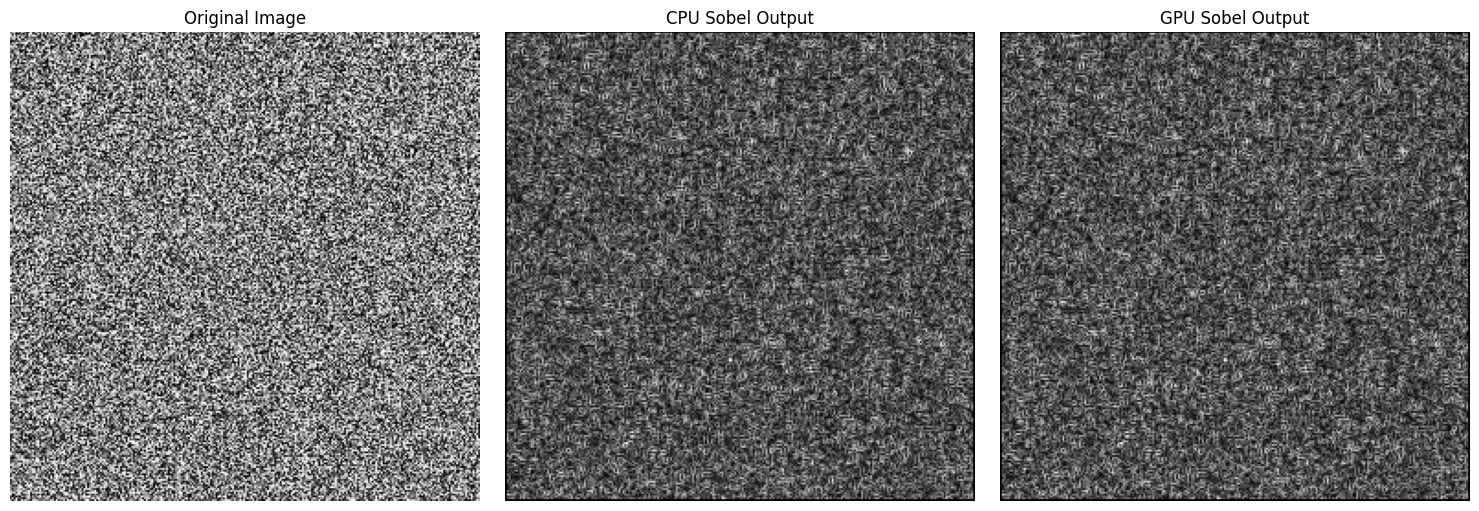

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cpu_edges, cmap="gray")
plt.title("CPU Sobel Output")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gpu_edges_result, cmap="gray")
plt.title("GPU Sobel Output")
plt.axis("off")

plt.tight_layout()
plt.show()

## CPU and GPU Performance Measurement

The execution time of the CPU and GPU Sobel implementations is measured to evaluate their computational performance.

Multiple executions are performed to obtain average execution times and reduce the effect of variations between individual runs.

GPU kernel execution is measured separately from memory transfers to understand the computational performance of the GPU.

In [ ]:
import time

# Number of repetitions
num_runs = 30

# Measure CPU execution time
cpu_times = []

for _ in range(num_runs):
    start = time.perf_counter()

    cpu_edges = sobel_cpu(image)

    end = time.perf_counter()

    cpu_times.append(end - start)

cpu_avg_time = np.mean(cpu_times)

print("CPU Performance")
print("-------------------------")
print("Number of runs:", num_runs)
print("Average execution time:", cpu_avg_time * 1000, "ms")

CPU Performance
-------------------------
Number of runs: 30
Average execution time: 0.8186607333224553 ms


In [ ]:
# Warm-up execution
sobel_kernel[blocks_per_grid, threads_per_block](
    gpu_image, gpu_edges
)
cuda.synchronize()

# Number of repetitions
gpu_runs = 100

# Create CUDA events
start_event = cuda.event()
end_event = cuda.event()

# Measure GPU kernel execution
start_event.record()

for _ in range(gpu_runs):
    sobel_kernel[blocks_per_grid, threads_per_block](
        gpu_image, gpu_edges
    )

end_event.record()
end_event.synchronize()

gpu_avg_time = cuda.event_elapsed_time(
    start_event, end_event
) / gpu_runs

print("GPU Kernel Performance")
print("-------------------------")
print("Number of runs:", gpu_runs)
print("Average kernel execution time:", gpu_avg_time, "ms")

GPU Kernel Performance
-------------------------
Number of runs: 100
Average kernel execution time: 0.08122367858886718 ms


In [ ]:
speedup = (cpu_avg_time * 1000) / gpu_avg_time

print("CPU vs GPU Performance")
print("-------------------------")
print("CPU average time:", cpu_avg_time * 1000, "ms")
print("GPU kernel average time:", gpu_avg_time, "ms")
print("GPU kernel speedup:", speedup, "x")

CPU vs GPU Performance
-------------------------
CPU average time: 0.8186607333224553 ms
GPU kernel average time: 0.08122367858886718 ms
GPU kernel speedup: 10.079089589949499 x


## GPU Memory Transfer and End-to-End Performance

GPU applications involve transferring input data from CPU memory to GPU memory and retrieving the computed results back to CPU memory.

In this experiment, Host-to-Device (H2D) and Device-to-Host (D2H) transfer times are measured separately.

The overall GPU execution time, including memory transfers and kernel execution, is also measured to evaluate the actual performance of GPU-based Sobel edge detection.

In [ ]:
import time
import numpy as np
from numba import cuda

input_float = image.astype(np.float32)

transfer_runs = 100
h2d_times = []

for _ in range(transfer_runs):
    cuda.synchronize()

    start = time.perf_counter()

    d_input = cuda.to_device(input_float)

    cuda.synchronize()
    end = time.perf_counter()

    h2d_times.append(end - start)

h2d_avg = np.mean(h2d_times) * 1000

print("Host-to-Device Transfer")
print("-------------------------")
print("Average H2D time:", h2d_avg, "ms")

Host-to-Device Transfer
-------------------------
Average H2D time: 0.30285125998489093 ms


In [ ]:
d_output = cuda.to_device(
    np.zeros(image.shape, dtype=np.float32)
)

# Warm-up copy
d_output.copy_to_host()

d2h_times = []

for _ in range(transfer_runs):
    cuda.synchronize()

    start = time.perf_counter()

    output_cpu = d_output.copy_to_host()

    cuda.synchronize()
    end = time.perf_counter()

    d2h_times.append(end - start)

d2h_avg = np.mean(d2h_times) * 1000

print("Device-to-Host Transfer")
print("-------------------------")
print("Average D2H time:", d2h_avg, "ms")

Device-to-Host Transfer
-------------------------
Average D2H time: 0.41608347000192225 ms


In [ ]:
total_runs = 30
total_gpu_times = []

for _ in range(total_runs):
    cuda.synchronize()

    start = time.perf_counter()

    # Transfer input to GPU
    d_input = cuda.to_device(input_float)

    # Allocate GPU output
    d_output = cuda.device_array(
        image.shape, dtype=np.float32
    )

    # Execute Sobel kernel
    sobel_kernel[blocks_per_grid, threads_per_block](
        d_input, d_output
    )

    # Transfer output back to CPU
    result = d_output.copy_to_host()

    cuda.synchronize()
    end = time.perf_counter()

    total_gpu_times.append(end - start)

total_gpu_avg = np.mean(total_gpu_times) * 1000

print("Complete GPU Execution")
print("-------------------------")
print("Average end-to-end time:", total_gpu_avg, "ms")

Complete GPU Execution
-------------------------
Average end-to-end time: 1.859148600002906 ms


In [ ]:
cpu_time_ms = cpu_avg_time * 1000

end_to_end_speedup = cpu_time_ms / total_gpu_avg

print("CPU vs GPU End-to-End Performance")
print("----------------------------------")
print("CPU execution time:", cpu_time_ms, "ms")
print("GPU H2D transfer time:", h2d_avg, "ms")
print("GPU kernel time:", gpu_avg_time, "ms")
print("GPU D2H transfer time:", d2h_avg, "ms")
print("GPU end-to-end time:", total_gpu_avg, "ms")
print("End-to-end speedup:", end_to_end_speedup, "x")

CPU vs GPU End-to-End Performance
----------------------------------
CPU execution time: 0.8186607333224553 ms
GPU H2D transfer time: 0.30285125998489093 ms
GPU kernel time: 0.08122367858886718 ms
GPU D2H transfer time: 0.41608347000192225 ms
GPU end-to-end time: 1.859148600002906 ms
End-to-end speedup: 0.44034174208623 x


## Performance Analysis Across Different Image Resolutions

The performance of CPU and GPU Sobel edge detection is evaluated using images of different resolutions.

The experiments use 256 × 256, 512 × 512, 1024 × 1024, and 2048 × 2048 images.

For each resolution, CPU execution time, GPU kernel execution time, and GPU end-to-end execution time are measured.

This experiment investigates how workload size affects GPU performance and the impact of memory-transfer overhead.

In [ ]:
import numpy as np
import time
from numba import cuda

resolutions = [256, 512, 1024, 2048]

results = []

for size in resolutions:

    print(f"\nTesting image size: {size} x {size}")

    # Generate input image
    rng = np.random.default_rng(42)
    test_image = rng.integers(
        0, 256,
        size=(size, size),
        dtype=np.uint8
    )

    test_float = test_image.astype(np.float32)

    # -------------------------
    # CPU PERFORMANCE
    # -------------------------

    # Warm-up
    sobel_cpu(test_image)

    cpu_times = []

    for _ in range(20):
        start = time.perf_counter()
        cpu_result = sobel_cpu(test_image)
        end = time.perf_counter()

        cpu_times.append(end - start)

    cpu_avg = np.mean(cpu_times) * 1000

    # -------------------------
    # GPU SETUP
    # -------------------------

    d_input = cuda.to_device(test_float)

    d_output = cuda.device_array(
        (size, size),
        dtype=np.float32
    )

    threads = (16, 16)

    blocks = (
        (size + threads[0] - 1) // threads[0],
        (size + threads[1] - 1) // threads[1]
    )

    # Warm-up GPU kernel
    sobel_kernel[blocks, threads](d_input, d_output)
    cuda.synchronize()

    # -------------------------
    # GPU KERNEL TIME
    # -------------------------

    start_event = cuda.event()
    end_event = cuda.event()

    start_event.record()

    for _ in range(50):
        sobel_kernel[blocks, threads](d_input, d_output)

    end_event.record()
    end_event.synchronize()

    gpu_kernel_avg = (
        cuda.event_elapsed_time(start_event, end_event) / 50
    )

    # -------------------------
    # GPU END-TO-END TIME
    # -------------------------

    total_times = []

    for _ in range(10):

        cuda.synchronize()
        start = time.perf_counter()

        d_in = cuda.to_device(test_float)

        d_out = cuda.device_array(
            (size, size),
            dtype=np.float32
        )

        sobel_kernel[blocks, threads](d_in, d_out)

        gpu_result = d_out.copy_to_host()

        cuda.synchronize()
        end = time.perf_counter()

        total_times.append(end - start)

    gpu_total_avg = np.mean(total_times) * 1000

    # Calculate speedups
    kernel_speedup = cpu_avg / gpu_kernel_avg
    total_speedup = cpu_avg / gpu_total_avg

    results.append({
        "Resolution": f"{size}x{size}",
        "CPU (ms)": cpu_avg,
        "GPU Kernel (ms)": gpu_kernel_avg,
        "GPU End-to-End (ms)": gpu_total_avg,
        "Kernel Speedup": kernel_speedup,
        "End-to-End Speedup": total_speedup
    })

    print("CPU average time:", cpu_avg, "ms")
    print("GPU kernel time:", gpu_kernel_avg, "ms")
    print("GPU end-to-end time:", gpu_total_avg, "ms")
    print("Kernel speedup:", kernel_speedup, "x")
    print("End-to-end speedup:", total_speedup, "x")


Testing image size: 256 x 256
CPU average time: 1.186794049999662 ms
GPU kernel time: 0.060686078071594235 ms
GPU end-to-end time: 1.5773113000705052 ms
Kernel speedup: 19.55628189713537 x
End-to-end speedup: 0.7524158673982827 x

Testing image size: 512 x 512
CPU average time: 4.598202150009456 ms
GPU kernel time: 0.21086528778076172 ms
GPU end-to-end time: 1.7944225000974257 ms
Kernel speedup: 21.806349439506814 x
End-to-end speedup: 2.562496931330165 x

Testing image size: 1024 x 1024
CPU average time: 15.180676100021628 ms
GPU kernel time: 0.8158003234863281 ms
GPU end-to-end time: 3.676926799971625 ms
Kernel speedup: 18.60832321706727 x
End-to-end speedup: 4.128631578996563 x

Testing image size: 2048 x 2048
CPU average time: 108.91993605007428 ms
GPU kernel time: 3.231422119140625 ms
GPU end-to-end time: 10.651691299972299 ms
Kernel speedup: 33.7065019778477 x
End-to-end speedup: 10.225600140172814 x


In [ ]:
import pandas as pd

results_df = pd.DataFrame(results)

print("Performance Comparison Across Image Resolutions")
display(results_df.round(4))

Performance Comparison Across Image Resolutions


,Resolution,CPU (ms),GPU Kernel (ms),GPU End-to-End (ms),Kernel Speedup,End-to-End Speedup
0,256x256,1.1868,0.0607,1.5773,19.5563,0.7524
1,512x512,4.5982,0.2109,1.7944,21.8063,2.5625
2,1024x1024,15.1807,0.8158,3.6769,18.6083,4.1286
3,2048x2048,108.9199,3.2314,10.6517,33.7065,10.2256


In [ ]:
print("Largest image GPU output verification:")

print(
    "Outputs are close:",
    np.allclose(
        cpu_result,
        gpu_result,
        rtol=1e-5,
        atol=1e-4
    )
)

Largest image GPU output verification:
Outputs are close: True


## Sobel Edge Detection on Real Images

In this experiment, a real grayscale photograph is used to evaluate the CPU and GPU implementations of Sobel edge detection.

The experiment demonstrates the effectiveness of the implementations on actual image content rather than randomly generated input data.

In [ ]:
!pip install scikit-image

Image shape: (512, 512)
Image data type: uint8


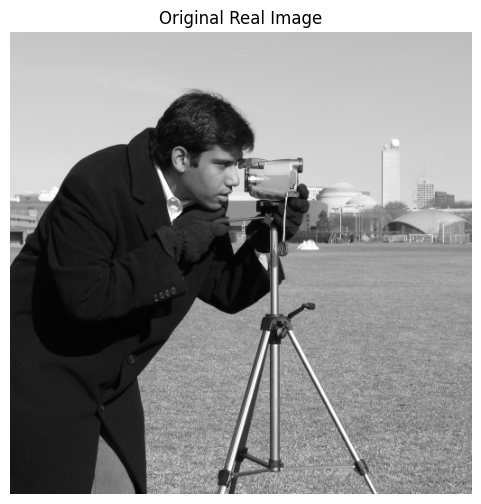

In [ ]:
from skimage import data
import matplotlib.pyplot as plt

# Load a real grayscale photograph
real_image = data.camera()

print("Image shape:", real_image.shape)
print("Image data type:", real_image.dtype)

# Display the original image
plt.figure(figsize=(6, 6))
plt.imshow(real_image, cmap="gray")
plt.title("Original Real Image")
plt.axis("off")
plt.show()

In [ ]:
# CPU Sobel
cpu_real_edges = sobel_cpu(real_image)

# Transfer image to GPU
real_image_float = real_image.astype(np.float32)
d_real_image = cuda.to_device(real_image_float)

# Allocate GPU output
d_real_edges = cuda.device_array(real_image.shape, dtype=np.float32)

# Calculate grid dimensions
threads = (16, 16)
blocks = (
    (real_image.shape[1] + threads[0] - 1) // threads[0],
    (real_image.shape[0] + threads[1] - 1) // threads[1]
)

# Run GPU Sobel
sobel_kernel[blocks, threads](d_real_image, d_real_edges)
cuda.synchronize()

# Copy GPU result to CPU
gpu_real_edges = d_real_edges.copy_to_host()

# Verify correctness
print("Maximum absolute difference:",
      np.max(np.abs(cpu_real_edges - gpu_real_edges)))

print("Outputs are close:",
      np.allclose(cpu_real_edges, gpu_real_edges,
                  rtol=1e-5, atol=1e-4))

Maximum absolute difference: 0.0
Outputs are close: True


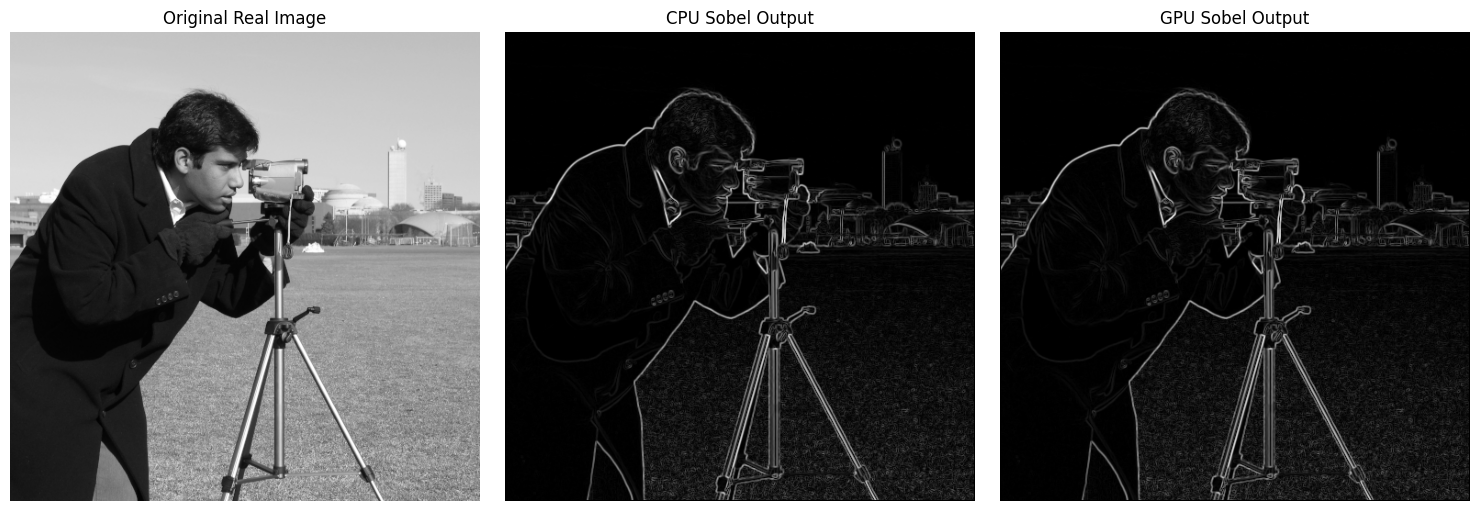

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(real_image, cmap="gray")
plt.title("Original Real Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cpu_real_edges, cmap="gray")
plt.title("CPU Sobel Output")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gpu_real_edges, cmap="gray")
plt.title("GPU Sobel Output")
plt.axis("off")

plt.tight_layout()
plt.show()

## Performance Comparison Across Thread-Block Configurations

The effect of CUDA thread-block configuration on GPU performance is evaluated using different numbers of threads per block.

The configurations 8 × 8, 16 × 16, and 32 × 32 are compared while keeping the input image and Sobel kernel unchanged.

In [ ]:
import time
import pandas as pd

thread_configs = [(8, 8), (16, 16), (32, 32)]
block_results = []

for threads in thread_configs:

    blocks = (
        (real_image.shape[1] + threads[0] - 1) // threads[0],
        (real_image.shape[0] + threads[1] - 1) // threads[1]
    )

    d_output = cuda.device_array(real_image.shape, dtype=np.float32)

    # Warm-up
    sobel_kernel[blocks, threads](d_real_image, d_output)
    cuda.synchronize()

    # Measure kernel execution time
    start_event = cuda.event()
    end_event = cuda.event()

    start_event.record()

    for _ in range(100):
        sobel_kernel[blocks, threads](d_real_image, d_output)

    end_event.record()
    end_event.synchronize()

    avg_time = cuda.event_elapsed_time(
        start_event, end_event
    ) / 100

    block_results.append({
        "Threads per Block": f"{threads[0]}x{threads[1]}",
        "Total Threads": threads[0] * threads[1],
        "GPU Kernel Time (ms)": avg_time
    })

block_df = pd.DataFrame(block_results)

print("Thread-Block Performance Comparison")
display(block_df.round(5))

Thread-Block Performance Comparison


,Threads per Block,Total Threads,GPU Kernel Time (ms)
0,8x8,64,0.21383
1,16x16,256,0.21326
2,32x32,1024,0.23284


In [ ]:
print("Thread-block configuration correctness:")

for threads in thread_configs:
    blocks = (
        (real_image.shape[1] + threads[0] - 1) // threads[0],
        (real_image.shape[0] + threads[1] - 1) // threads[1]
    )

    d_output = cuda.device_array(real_image.shape, dtype=np.float32)

    sobel_kernel[blocks, threads](d_real_image, d_output)
    cuda.synchronize()

    output = d_output.copy_to_host()

    print(
        f"{threads}:",
        np.allclose(cpu_real_edges, output, rtol=1e-5, atol=1e-4)
    )

Thread-block configuration correctness:
(8, 8): True
(16, 16): True
(32, 32): True


## Performance Visualization

The experimental results are visualized using graphs to compare CPU and GPU execution times, kernel speedup, and end-to-end speedup across different image resolutions.

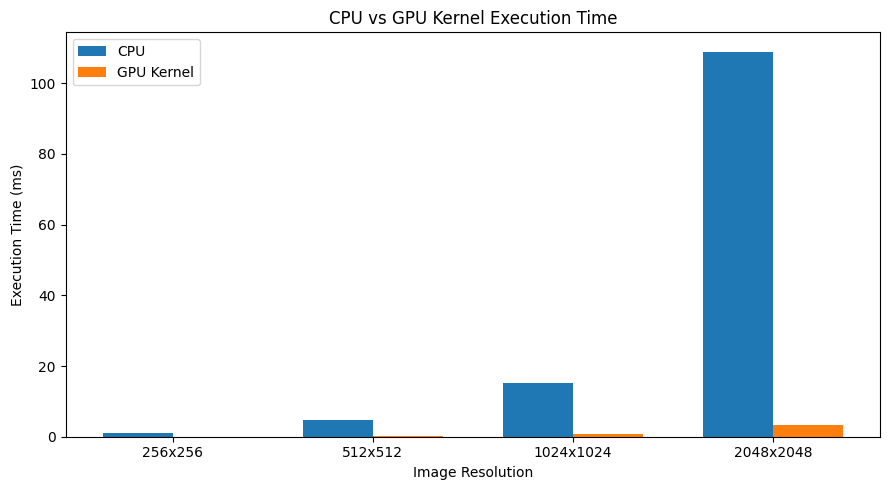

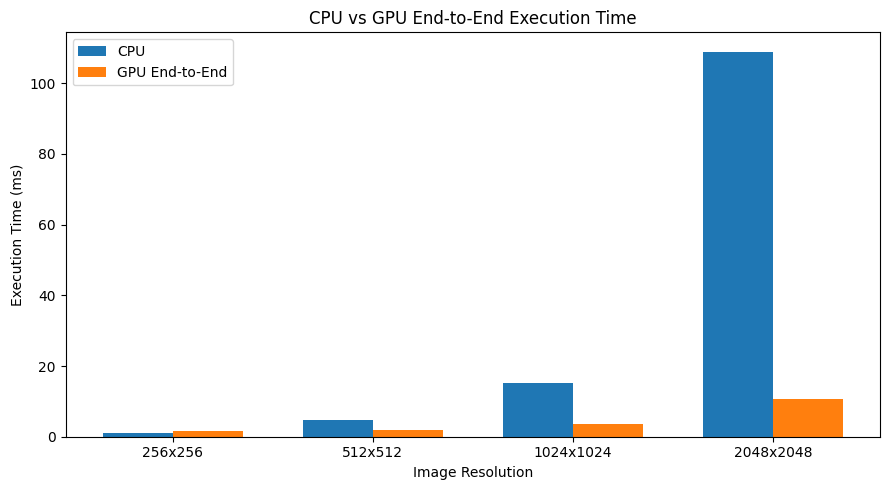

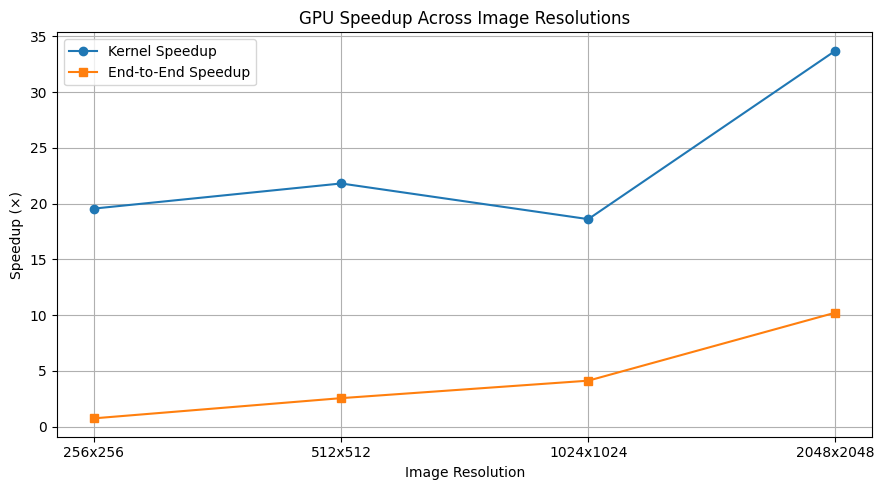

In [34]:
import matplotlib.pyplot as plt
import numpy as np

# Extract values from the existing results table
resolutions = results_df["Resolution"]
cpu_times = results_df["CPU (ms)"]
gpu_kernel_times = results_df["GPU Kernel (ms)"]
gpu_total_times = results_df["GPU End-to-End (ms)"]

# Graph 1: CPU vs GPU Kernel Time
x = np.arange(len(resolutions))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, cpu_times, width, label="CPU")
plt.bar(x + width/2, gpu_kernel_times, width, label="GPU Kernel")

plt.xlabel("Image Resolution")
plt.ylabel("Execution Time (ms)")
plt.title("CPU vs GPU Kernel Execution Time")
plt.xticks(x, resolutions)
plt.legend()
plt.tight_layout()
plt.savefig("cpu_vs_gpu_kernel.png", dpi=300, bbox_inches="tight")
plt.show()


# Graph 2: CPU vs GPU End-to-End Time
plt.figure(figsize=(9, 5))
plt.bar(x - width/2, cpu_times, width, label="CPU")
plt.bar(x + width/2, gpu_total_times, width, label="GPU End-to-End")

plt.xlabel("Image Resolution")
plt.ylabel("Execution Time (ms)")
plt.title("CPU vs GPU End-to-End Execution Time")
plt.xticks(x, resolutions)
plt.legend()
plt.tight_layout()
plt.savefig("cpu_vs_gpu_end_to_end.png", dpi=300, bbox_inches="tight")
plt.show()


# Graph 3: Speedup Comparison
plt.figure(figsize=(9, 5))
plt.plot(resolutions, results_df["Kernel Speedup"],
         marker="o", label="Kernel Speedup")
plt.plot(resolutions, results_df["End-to-End Speedup"],
         marker="s", label="End-to-End Speedup")

plt.xlabel("Image Resolution")
plt.ylabel("Speedup (×)")
plt.title("GPU Speedup Across Image Resolutions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("gpu_speedup_comparison.png", dpi=300, bbox_inches="tight")
plt.show()